# Automated PCB Defect Detection Using Classical Image Processing Techniques

**Course:** ARTI 403 – Image Processing

**Group:** 2

**Team Members:**
- Sarah Khalid Bahwal
- Sara Abdulaziz Al-Qatari
- Dina Moteb Almsnid
- Raghad Mohammed Alsheddi
- Hawra Habib Alali
- Danah Eid Aldossary

This notebook detects open and short defects on PCB images from the DeepPCB dataset using classical image processing only (Python and OpenCV, no deep learning). Each test image is compared with its defect-free template, the difference is thresholded and cleaned, and the remaining regions are marked with bounding boxes. The boxes are then compared with the ground truth using IoU, Precision, Recall and F1-score.

**Contents**
1. Data Loading
2. Preprocessing
3. Thresholding and Morphology
4. Contour Detection and Bounding Boxes
5. Evaluation
6. Experiments and Results

## 1. Data Loading

This part reads the DeepPCB train and test files. For each sample it loads
the test image, its defect-free template, and the open/short boxes. The other
parts use them for the detection and the evaluation.

### 1.1 Download the dataset

Downloads DeepPCB from GitHub if the folder is not already here.

In [1]:

import os

if not os.path.exists("DeepPCB"):
    !git clone https://github.com/tangsanli5201/DeepPCB.git

Cloning into 'DeepPCB'...
remote: Enumerating objects: 4753, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4753 (delta 13), reused 12 (delta 12), pack-reused 4739 (from 1)
Receiving objects: 100% (4753/4753), 85.81 MiB | 25.73 MiB/s, done.
Resolving deltas: 100% (191/191), done.
Updating files: 100% (4548/4548), done.


### 1.2 Loading functions

Functions that read the train and test lists, load a test image with its template and the open/short boxes, count the defects, and save example images.

In [2]:
import os
import cv2
from collections import Counter

# path to the dataset folder
ROOT = "DeepPCB/PCBData"

# defect type numbers from the annotation files
NAMES = {1: "open", 2: "short", 3: "mousebite", 4: "spur", 5: "copper", 6: "pin-hole"}
# only open and short for our project
KEEP = {1, 2}


# reads trainval.txt or test.txt
def list_samples(split="train"):
    fname = "trainval.txt" if split == "train" else "test.txt"
    samples = []
    with open(os.path.join(ROOT, fname)) as f:
        for line in f:
            parts = line.replace(",", " ").split()
            if len(parts) >= 2:
                samples.append((parts[0].replace(".jpg", ""), parts[1]))
    return samples


# returns test image, template, and the boxes (x1, y1, x2, y2, type)
def load_pair(sample):
    img_path, ann_path = sample
    test = cv2.imread(os.path.join(ROOT, img_path + "_test.jpg"), cv2.IMREAD_GRAYSCALE)
    temp = cv2.imread(os.path.join(ROOT, img_path + "_temp.jpg"), cv2.IMREAD_GRAYSCALE)

    boxes = []
    with open(os.path.join(ROOT, ann_path)) as f:
        for line in f:
            p = line.replace(",", " ").split()
            if len(p) == 5 and int(p[4]) in KEEP:
                boxes.append((int(p[0]), int(p[1]), int(p[2]), int(p[3]), int(p[4])))
    return test, temp, boxes


# number of defects per type
def stats(split="train"):
    counter = Counter()
    for s in list_samples(split):
        _, _, boxes = load_pair(s)
        counter.update(NAMES[b[4]] for b in boxes)
    return counter


# saves the images we use in the report
def save_example(sample, out_dir="examples", name="example"):
    os.makedirs(out_dir, exist_ok=True)
    test, temp, boxes = load_pair(sample)

    # green boxes = ground truth
    vis = cv2.cvtColor(test, cv2.COLOR_GRAY2BGR)
    for x1, y1, x2, y2, t in boxes:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(vis, NAMES[t], (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    cv2.imwrite(os.path.join(out_dir, f"{name}_template.png"), temp)
    cv2.imwrite(os.path.join(out_dir, f"{name}_test.png"), test)
    cv2.imwrite(os.path.join(out_dir, f"{name}_gt.png"), vis)

### 1.3 Dataset statistics

Prints the number of image pairs and the number of open and short defects in the train and test splits.

In [3]:
for sp in ("train", "test"):
    print(f"{sp}: {len(list_samples(sp))} pairs, defects = {dict(stats(sp))}")

train: 1000 pairs, defects = {'open': 1283, 'short': 1028}
test: 500 pairs, defects = {'open': 659, 'short': 478}


### 1.4 Example images

Saves three examples that have open or short defects (template, test image, and the ground truth boxes in green) and shows them.

In [4]:
# skip images with no open/short defect
shown = 0
for s in list_samples("train"):
    _, _, boxes = load_pair(s)
    if boxes:
        shown += 1
        save_example(s, name=f"example{shown}")
        if shown == 3:
            break

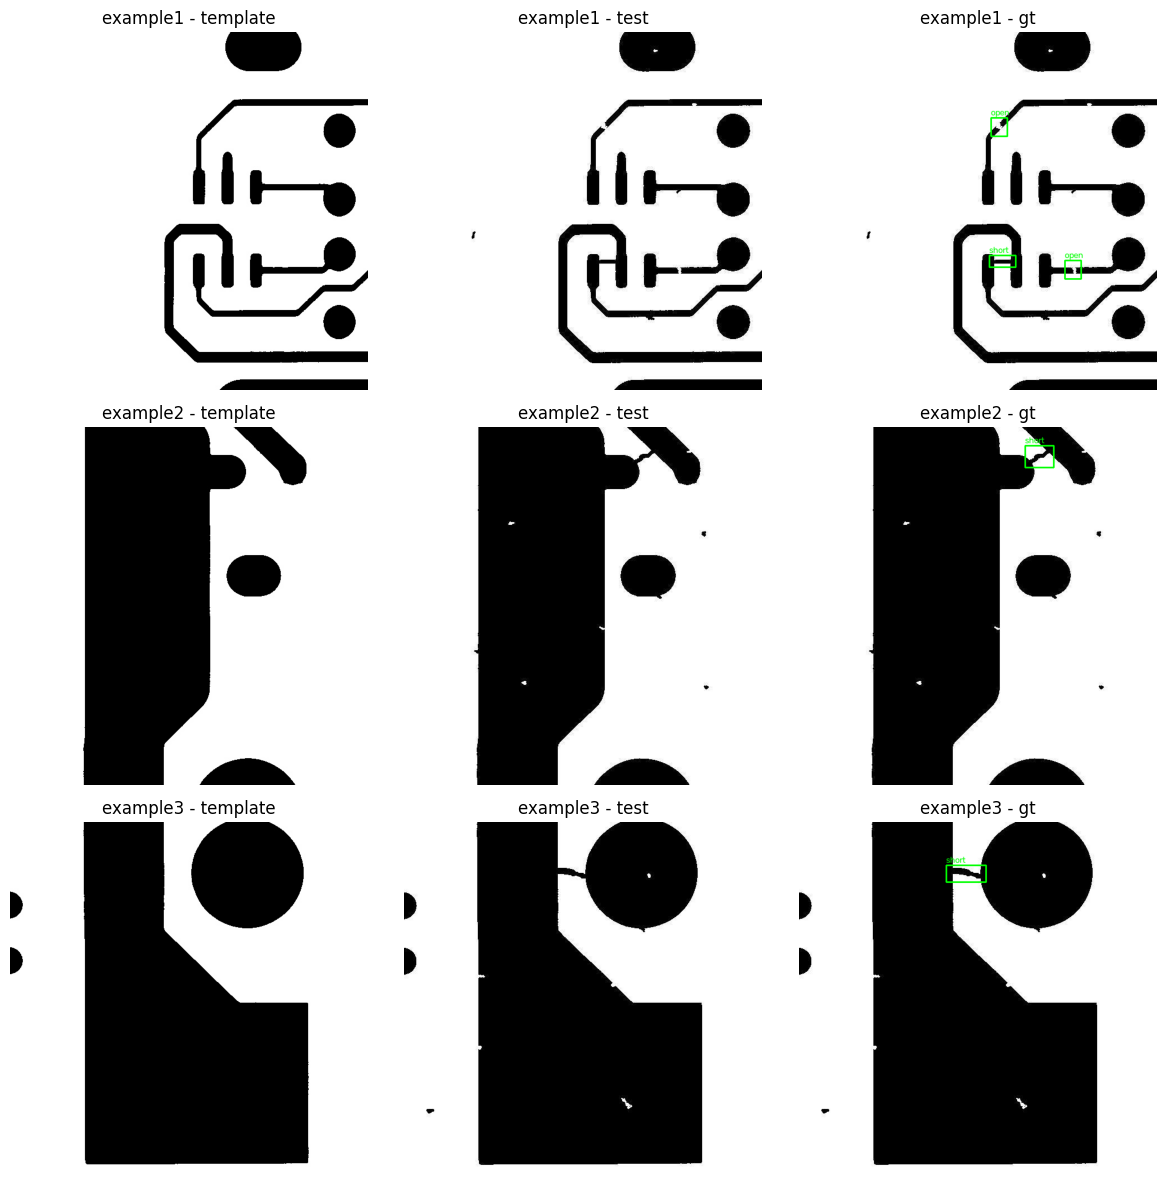

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    for j, kind in enumerate(["template", "test", "gt"]):
        img = cv2.imread(f"examples/example{i + 1}_{kind}.png")
        axes[i][j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i][j].set_title(f"example{i + 1} - {kind}")
        axes[i][j].axis("off")
plt.tight_layout()
plt.show()

## 2. Preprocessing

`difference(test, temp, blur, k)` converts the test image and its template to grayscale, applies the chosen noise filter (`none`, `gaussian` or `median`, with an odd size `k`) and returns the absolute difference. Bright pixels in the result show where the test image differs from the template.

The cell below saves this code as `preprocess.py` so the later sections can import it.

In [ ]:
%%writefile preprocess.py
"""
Role 2 - Preprocessing & Subtraction
ARTI 403 - Group 2 - Automated PCB Defect Detection

Interface (agreed between roles):
    difference(test, temp, blur, k) -> diff image

    test  : defective image (BGR or grayscale, numpy array)
    temp  : defect-free template image (same size as test)
    blur  : "none" | "gaussian" | "median"
    k     : filter size (odd number, e.g. 3, 5, 7). Ignored when blur="none".

Returns a single-channel uint8 image where bright pixels show
where the test image differs from the template (possible defects).
"""

import cv2

# Settings that Role 6 can change in experiments
BLUR_OPTIONS = ("none", "gaussian", "median")
DEFAULT_BLUR = "gaussian"
DEFAULT_K = 5


def to_gray(img):
    """Convert to grayscale if the image has 3 channels."""
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img


def denoise(gray, blur=DEFAULT_BLUR, k=DEFAULT_K):
    """Apply the chosen noise-removal filter to a grayscale image."""
    blur = blur.lower()
    if blur not in BLUR_OPTIONS:
        raise ValueError(f"blur must be one of {BLUR_OPTIONS}, got '{blur}'")
    if blur == "none":
        return gray
    if k < 1 or k % 2 == 0:
        raise ValueError(f"k must be a positive odd number, got {k}")
    if blur == "gaussian":
        return cv2.GaussianBlur(gray, (k, k), 0)
    return cv2.medianBlur(gray, k)  # median


def difference(test, temp, blur=DEFAULT_BLUR, k=DEFAULT_K):
    """Grayscale -> denoise -> absolute difference."""
    if test.shape[:2] != temp.shape[:2]:
        raise ValueError(f"image sizes differ: {test.shape[:2]} vs {temp.shape[:2]}")
    test_g = denoise(to_gray(test), blur, k)
    temp_g = denoise(to_gray(temp), blur, k)
    return cv2.absdiff(test_g, temp_g)


if __name__ == "__main__":
    # Quick standalone test (does not need Role 1's code):
    #   python preprocess.py path/to/xxx_test.jpg path/to/xxx_temp.jpg
    import sys

    if len(sys.argv) != 3:
        print("usage: python preprocess.py <test.jpg> <temp.jpg>")
        sys.exit(1)
    test_img = cv2.imread(sys.argv[1])
    temp_img = cv2.imread(sys.argv[2])
    for b in BLUR_OPTIONS:
        d = difference(test_img, temp_img, b, DEFAULT_K)
        out = f"diff_{b}.png"
        cv2.imwrite(out, d)
        print(f"{b:9s} -> {out}  (non-zero pixels: {(d > 0).sum()})")

## 3. Thresholding and Morphology

This notebook turns the difference image (test image minus template) into a black and white mask where the defects are white. It tries three threshold methods (fixed, Otsu, and adaptive), then cleans the mask with opening (removes small white dots) and closing (fills small holes). The kernel size and the other settings can be changed for the experiments. The mask is then used by the contour part to draw the bounding boxes.

### 3.1 The make_mask function

`make_mask` takes the difference image and returns a mask of 0 and 255.

- `method`: `fixed`, `otsu`, or `adaptive`
- `thresh`: threshold value for the fixed method
- `block` and `c`: window size and constant for the adaptive method
- `k`: kernel size for opening and closing (3, 5, or 7)
- `morph`: turns opening and closing on or off

`save_examples` saves the pictures for the report.

In [3]:
import os
import cv2
import numpy as np

# default settings, the experiments part changes them
THRESH = 50
BLOCK = 31
C = -25
KERNEL = 3


# diff = grayscale difference image (uint8)
# returns a mask of 0 and 255
def make_mask(diff, method="otsu", thresh=THRESH, block=BLOCK, c=C, k=KERNEL, morph=True):
    if method == "fixed":
        _, mask = cv2.threshold(diff, thresh, 255, cv2.THRESH_BINARY)
    elif method == "otsu":
        _, mask = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif method == "adaptive":
        # c is negative because the diff image is mostly black
        mask = cv2.adaptiveThreshold(diff, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, block, c)
    else:
        raise ValueError("method must be fixed, otsu or adaptive")

    if morph and k > 1:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        # opening removes small white dots, closing fills small holes
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask


# adds a title on the image and makes it 3 channels
def label(img, title):
    out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    cv2.putText(out, title, (6, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    return out


# cuts a window around the defect box and makes it bigger so it is easy to see
def crop(img, box, size=160, scale=3):
    x1, y1, x2, y2 = box[:4]
    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    x0 = int(np.clip(cx - size // 2, 0, img.shape[1] - size))
    y0 = int(np.clip(cy - size // 2, 0, img.shape[0] - size))
    win = img[y0:y0 + size, x0:x0 + size]
    return cv2.resize(win, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)


# saves two pictures for the report: the three methods, and before/after morphology
def save_examples(diff, box, out_dir="examples", name="threshold"):
    os.makedirs(out_dir, exist_ok=True)

    panels = [label(crop(diff, box), "difference")]
    for m in ("fixed", "otsu", "adaptive"):
        panels.append(label(crop(make_mask(diff, m), box), m))
    grid = np.vstack([np.hstack(panels[:2]), np.hstack(panels[2:])])
    cv2.imwrite(os.path.join(out_dir, f"{name}_methods.png"), grid)

    before = label(crop(make_mask(diff, "otsu", morph=False), box), "otsu, no morphology")
    after = label(crop(make_mask(diff, "otsu"), box), "otsu + opening/closing")
    cv2.imwrite(os.path.join(out_dir, f"{name}_morphology.png"), np.hstack([before, after]))

### 3.2 Example

The difference image here is temporary (Gaussian blur, then `absdiff`) until the preprocessing part is ready. The cell prints the number of white pixels for each method and saves the pictures.

In [4]:
for s in list_samples("train"):
    test, temp, boxes = load_pair(s)
    if boxes:
        break
diff = cv2.absdiff(cv2.GaussianBlur(test, (3, 3), 0), cv2.GaussianBlur(temp, (3, 3), 0))

for m in ("fixed", "otsu", "adaptive"):
    mask = make_mask(diff, m)
    print(m, "white pixels:", int((mask > 0).sum()))
save_examples(diff, boxes[0])

fixed white pixels: 3570
otsu white pixels: 3928
adaptive white pixels: 3980


### 3.3 Results

Left: the three methods compared. Right: Otsu before and after opening and closing.

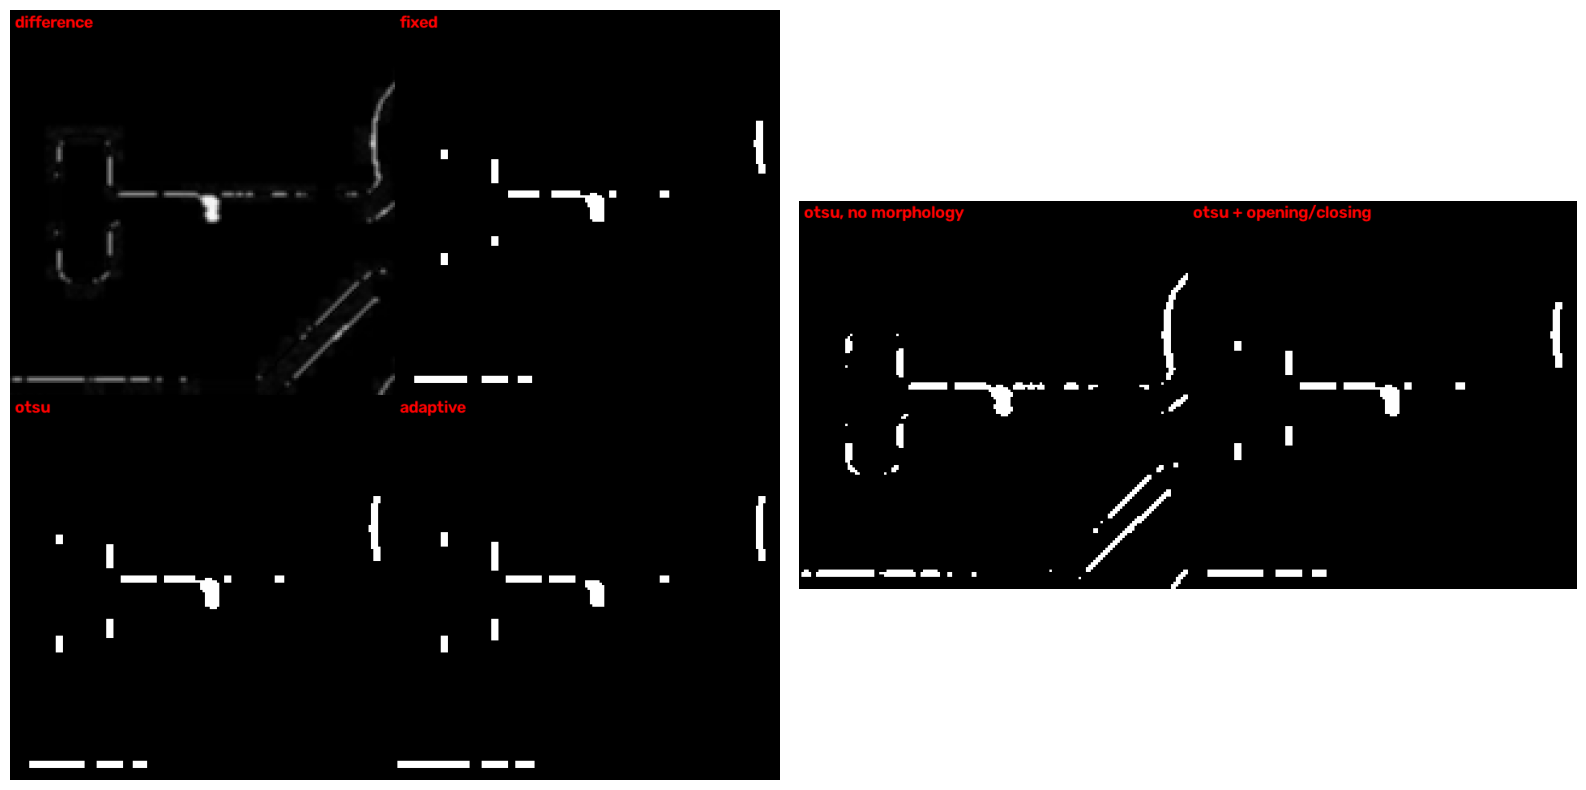

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, f in zip(axes, ["threshold_methods", "threshold_morphology"]):
    ax.imshow(cv2.cvtColor(cv2.imread(f"examples/{f}.png"), cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()
plt.show()

The cell below saves the final `make_mask` as `threshold.py` so the pipeline can import it.

In [ ]:
%%writefile threshold.py
import cv2

THRESH = 50
BLOCK = 31
C = -25
KERNEL = 3

def make_mask(diff, method="otsu", thresh=THRESH,
              block=BLOCK, c=C, k=KERNEL, morph=True):

    # Convert the difference image into a binary mask
    if method == "fixed":
        _, mask = cv2.threshold(
            diff, thresh, 255, cv2.THRESH_BINARY
        )

    elif method == "otsu":
        _, mask = cv2.threshold(
            diff, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

    elif method == "adaptive":
        mask = cv2.adaptiveThreshold(
            diff, 255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, block, c
        )

    else:
        raise ValueError("method must be fixed, otsu or adaptive")

    # Remove small noise and refine detected regions
    if morph and k > 1:
        kernel = cv2.getStructuringElement(
            cv2.MORPH_RECT, (k, k)
        )

        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    return mask

## 4. Contour Detection and Bounding Boxes

This part finds the contours in the binary mask, removes the small ones with a minimum area, and returns one bounding box for each remaining region. It ends with the pipeline that connects the preprocessing, thresholding and detection modules.

### 4.1 Contour Detection on a Synthetic Mask

A small test on a synthetic mask (a square and a circle) to see how the contours are found.

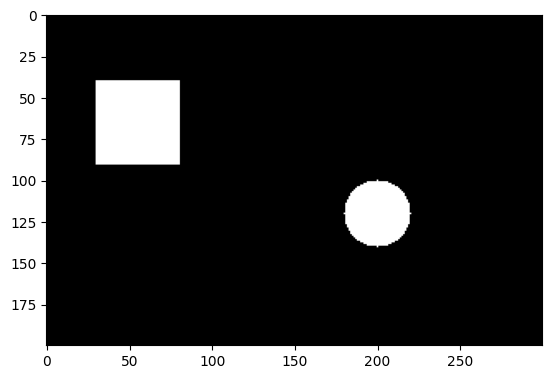

In [68]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

mask = np.zeros((200, 300), dtype=np.uint8)

cv2.rectangle(mask, (30, 40), (80, 90), 255, -1)
cv2.circle(mask, (200, 120), 20, 255, -1)

plt.imshow(mask, cmap="gray")
plt.show()

In [69]:
contours, _ = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Number of contours:", len(contours))

Number of contours: 2


In [70]:
boxes = []
min_area = 100

for contour in contours:
    area = cv2.contourArea(contour)

    if area >= min_area:
        x, y, w, h = cv2.boundingRect(contour)
        boxes.append((x, y, x + w, y + h))

print("Detected boxes:", boxes)

Detected boxes: [(180, 100, 221, 141), (30, 40, 81, 91)]


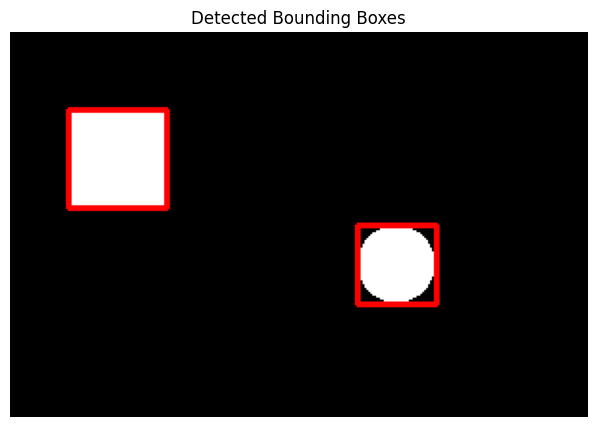

In [71]:
result = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)

for x1, y1, x2, y2 in boxes:
    cv2.rectangle(
        result,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Detected Bounding Boxes")
plt.axis("off")
plt.show()

### 4.2 Bounding Box Detection Function

`find_boxes` finds the external contours, ignores the ones smaller than `min_area`, and returns the bounding boxes, with optional padding.

In [72]:
def find_boxes(binary, min_area=100, pad=0):
    # Find contours in the binary image
    contours, _ = cv2.findContours(
        binary.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []
    height, width = binary.shape[:2]

    for contour in contours:
        # Ignore small regions
        area = cv2.contourArea(contour)

        if area >= min_area:
            # Get bounding box coordinates
            x, y, w, h = cv2.boundingRect(contour)

            # Add padding without exceeding image boundaries
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(width, x + w + pad)
            y2 = min(height, y + h + pad)

            boxes.append((x1, y1, x2, y2))

    return boxes

In [73]:
detected_boxes = find_boxes(mask, min_area=100)

print("Number of boxes:", len(detected_boxes))
print("Boxes:", detected_boxes)

Number of boxes: 2
Boxes: [(180, 100, 221, 141), (30, 40, 81, 91)]


In [74]:
for area in [100, 1000, 2000, 3000]:
    detected = find_boxes(mask, min_area=area)
    print(f"min_area={area}: {len(detected)} boxes")

min_area=100: 2 boxes
min_area=1000: 2 boxes
min_area=2000: 1 boxes
min_area=3000: 0 boxes


### 4.3 Thresholding and Detection on DeepPCB

Uses the thresholding function on a real DeepPCB image. The difference image becomes a binary mask, then the boxes are detected and drawn.

The binary mask is generated using the thresholding function developed by Danah Eid.

In [75]:
import os
import cv2
import numpy as np

# default settings, the experiments part changes them
THRESH = 50
BLOCK = 31
C = -25
KERNEL = 3


# diff = grayscale difference image (uint8)
# returns a mask of 0 and 255
def make_mask(diff, method="otsu", thresh=THRESH, block=BLOCK, c=C, k=KERNEL, morph=True):
    if method == "fixed":
        _, mask = cv2.threshold(diff, thresh, 255, cv2.THRESH_BINARY)
    elif method == "otsu":
        _, mask = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif method == "adaptive":
        # c is negative because the diff image is mostly black
        mask = cv2.adaptiveThreshold(diff, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, block, c)
    else:
        raise ValueError("method must be fixed, otsu or adaptive")

    if morph and k > 1:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        # opening removes small white dots, closing fills small holes
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask

In [76]:
# Test
diff = mask.copy()

binary = make_mask(diff, method="otsu")
boxes = find_boxes(binary, min_area=100)

print("Number of boxes:", len(boxes))
print("Detected boxes:", boxes)

Number of boxes: 2
Detected boxes: [(181, 101, 220, 140), (30, 40, 81, 91)]


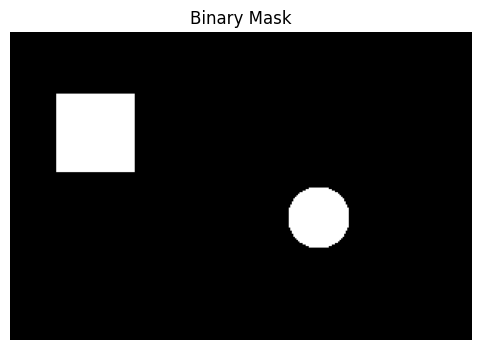

In [77]:
plt.figure(figsize=(7, 4))
plt.imshow(binary, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")
plt.show()

In [78]:
# Download DeepPCB only if it is not already available
!test -d DeepPCB/PCBData || git clone https://github.com/tangsanli5201/DeepPCB.git

In [79]:
from preprocess import difference

In [80]:
# Load the PCB test and template images
test = cv2.imread(
    "DeepPCB/PCBData/group00041/00041/00041000_test.jpg"
)

temp = cv2.imread(
    "DeepPCB/PCBData/group00041/00041/00041000_temp.jpg"
)

if test is None or temp is None:
    raise FileNotFoundError("PCB images could not be loaded")

print("Test image:", test.shape)
print("Template image:", temp.shape)

Test image: (640, 640, 3)
Template image: (640, 640, 3)


In [81]:
# Process the PCB image pair
pcb_diff = difference(test, temp, blur="median", k=5)

# Create a binary mask
pcb_binary = make_mask(pcb_diff, method="otsu")

# Detect possible defects
pcb_boxes = find_boxes(pcb_binary, min_area=100)

print("Test shape:", test.shape)
print("Binary shape:", pcb_binary.shape)
print("Number of boxes:", len(pcb_boxes))
print("Boxes:", pcb_boxes)

Test shape: (640, 640, 3)
Binary shape: (640, 640)
Number of boxes: 3
Boxes: [(100, 479, 117, 487), (467, 317, 484, 382), (551, 271, 583, 304)]


In [82]:
# Test the updated function
test_boxes = find_boxes(pcb_binary, min_area=150, pad=0)

print("Number of boxes:", len(test_boxes))
print("Boxes:", test_boxes)

Number of boxes: 2
Boxes: [(467, 317, 484, 382), (551, 271, 583, 304)]


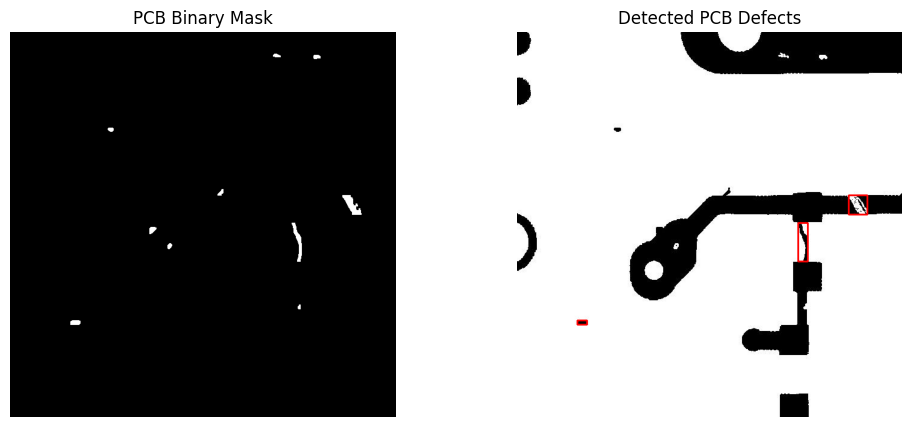

In [83]:
# Draw the detected boxes on the PCB image
pcb_result = test.copy()

for x1, y1, x2, y2 in pcb_boxes:
    cv2.rectangle(
        pcb_result,
        (x1, y1),
        (x2 - 1, y2 - 1),
        (0, 0, 255),
        2
    )

# Display the binary mask and detection results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(pcb_binary, cmap="gray")
plt.title("PCB Binary Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(pcb_result, cv2.COLOR_BGR2RGB))
plt.title("Detected PCB Defects")
plt.axis("off")

plt.show()

### 4.4 Ground Truth and IoU Comparison

Loads the ground truth boxes of the same image and compares them with the predicted boxes using IoU.

In [84]:
# Load the ground truth annotations
annotation_path = "DeepPCB/PCBData/group00041/00041_not/00041000.txt"

gt_boxes = []

with open(annotation_path, "r") as file:
    for line in file:
        x1, y1, x2, y2, defect_type = map(int, line.split())

        if defect_type in [1, 2]:
            gt_boxes.append((x1, y1, x2, y2, defect_type))

print("Ground Truth:", gt_boxes)

Ground Truth: [(454, 300, 493, 396, 2), (539, 259, 592, 316, 1)]


In [85]:
# Draw ground truth boxes
gt_result = test.copy()

for x1, y1, x2, y2, defect_type in gt_boxes:
    cv2.rectangle(
        gt_result,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

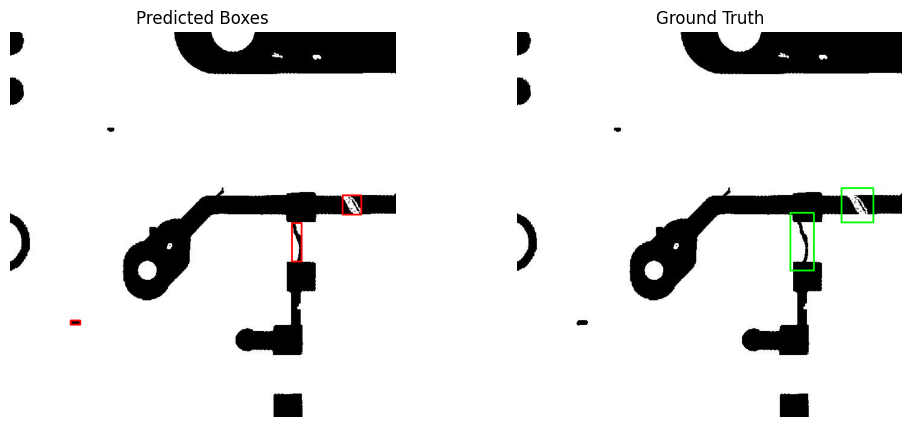

In [86]:
# Compare detected boxes with ground truth
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(pcb_result, cv2.COLOR_BGR2RGB))
plt.title("Predicted Boxes")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(gt_result, cv2.COLOR_BGR2RGB))
plt.title("Ground Truth")
plt.axis("off")

plt.show()

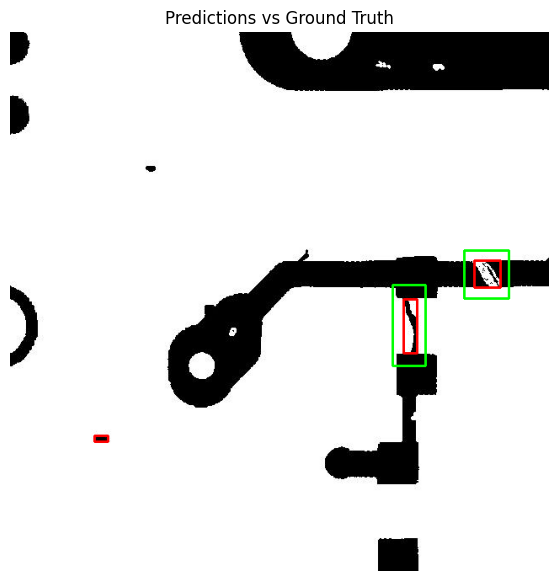

In [87]:
# Compare predictions and ground truth
comparison = test.copy()

# Predicted boxes in red
for x1, y1, x2, y2 in pcb_boxes:
    cv2.rectangle(comparison, (x1, y1), (x2-1, y2-1),
                  (0, 0, 255), 2)

# Ground truth boxes in green
for x1, y1, x2, y2, defect_type in gt_boxes:
    cv2.rectangle(comparison, (x1, y1), (x2, y2),
                  (0, 255, 0), 2)

plt.figure(figsize=(8, 7))
plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
plt.title("Predictions vs Ground Truth")
plt.axis("off")
plt.show()

In [88]:
# Calculate overlap between two boxes
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [89]:
# Check IoU for each detected box
for i, pred in enumerate(pcb_boxes, start=1):
    scores = [
        calculate_iou(pred, gt[:4])
        for gt in gt_boxes
    ]

    best_iou = max(scores, default=0)

    print(f"Box {i}: Best IoU = {best_iou:.3f}")

Box 1: Best IoU = 0.000
Box 2: Best IoU = 0.295
Box 3: Best IoU = 0.350


### 4.5 Minimum Area Experiments

The minimum contour area is tested using different values. These results are preliminary and are not used to select the final parameter.

In [90]:
# Check contour areas
contours, _ = cv2.findContours(
    pcb_binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

for contour in contours:
    area = cv2.contourArea(contour)

    if area >= 100:
        x, y, w, h = cv2.boundingRect(contour)
        print("Area:", area, "Box:", (x, y, x+w, y+h))

Area: 105.5 Box: (100, 479, 117, 487)
Area: 322.0 Box: (467, 317, 484, 382)
Area: 420.5 Box: (551, 271, 583, 304)


In [91]:
# Compare different minimum areas
for area in [100, 150, 200, 300]:
    new_boxes = find_boxes(pcb_binary, min_area=area)

    print(f"min_area={area}: {len(new_boxes)} boxes")

min_area=100: 3 boxes
min_area=150: 2 boxes
min_area=200: 2 boxes
min_area=300: 2 boxes


In [92]:
# Compare detected boxes with the ground truth
for area in [100, 150, 200, 300]:
    new_boxes = find_boxes(pcb_binary, min_area=area)

    print(f"\nmin_area = {area}")

    for i, pred in enumerate(new_boxes, start=1):
        scores = [
            calculate_iou(pred, gt[:4])
            for gt in gt_boxes
        ]

        print(f"Box {i}: IoU = {max(scores, default=0):.3f}")


min_area = 100
Box 1: IoU = 0.000
Box 2: IoU = 0.295
Box 3: IoU = 0.350

min_area = 150
Box 1: IoU = 0.295
Box 2: IoU = 0.350

min_area = 200
Box 1: IoU = 0.295
Box 2: IoU = 0.350

min_area = 300
Box 1: IoU = 0.295
Box 2: IoU = 0.350


### 4.6 Exporting the Detection Module

Saves `find_boxes` as `detection.py` so the pipeline can import it.

In [93]:
%%writefile detection.py
import cv2

def find_boxes(binary, min_area=100, pad=0):
    # Find contours in the binary image
    contours, _ = cv2.findContours(
        binary.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []
    height, width = binary.shape[:2]

    for contour in contours:
        # Ignore small regions
        area = cv2.contourArea(contour)

        if area >= min_area:
            # Get bounding box coordinates
            x, y, w, h = cv2.boundingRect(contour)

            # Add padding without exceeding image boundaries
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(width, x + w + pad)
            y2 = min(height, y + h + pad)

            boxes.append((x1, y1, x2, y2))

    return boxes

Overwriting detection.py


In [94]:
from detection import find_boxes

detected = find_boxes(pcb_binary, min_area=150, pad=0)

print("Number of boxes:", len(detected))
print("Detected boxes:", detected)

Number of boxes: 2
Detected boxes: [(467, 317, 484, 382), (551, 271, 583, 304)]


### 4.7 Pipeline Integration

This notebook integrates preprocessing, thresholding, and bounding box detection to identify potential PCB defects using DeepPCB images.

#### 4.7.1 Setup and Image Loading

**Required modules:** preprocess.py, threshold.py, detection.py

**Dataset:** DeepPCB

The pipeline was first tested with `min_area=150` to verify the integration. The final selected configuration was also tested using fixed thresholding (T=50), no filtering or morphology, `min_area=200`, and `pad=0`.

The visualization in Section 4 shows the initial integration test.

In [10]:
import cv2
import matplotlib.pyplot as plt

# Download the dataset if needed
!test -d DeepPCB/PCBData || git clone https://github.com/tangsanli5201/DeepPCB.git

# Load the PCB image pair
test = cv2.imread("DeepPCB/PCBData/group00041/00041/00041000_test.jpg")
temp = cv2.imread("DeepPCB/PCBData/group00041/00041/00041000_temp.jpg")

if test is None or temp is None:
    raise FileNotFoundError("PCB images could not be loaded")

print("Test:", test.shape)
print("Template:", temp.shape)

Test: (640, 640, 3)
Template: (640, 640, 3)


#### 4.7.2 Pipeline Implementation

Saves `run_pipeline` as `pipeline.py`. It runs the preprocessing, thresholding, and detection in one call and returns the difference image, the mask, and the boxes.

In [17]:
%%writefile pipeline.py
from preprocess import difference
from threshold import make_mask
from detection import find_boxes

def run_pipeline(test, temp, min_area=100, pad=0,
                 blur="median", k=5, method="otsu",
                 morph=True, thresh=50, kernel_size=3):

    # Calculate image differences
    diff = difference(test, temp, blur=blur, k=k)

    # Generate the binary mask
    mask = make_mask(
        diff, method=method, thresh=thresh,
        k=kernel_size, morph=morph
    )

    # Detect possible defect regions
    boxes = find_boxes(mask, min_area=min_area, pad=pad)

    return diff, mask, boxes

Writing pipeline.py


In [18]:
import importlib
import pipeline

# Reload the updated pipeline module
importlib.reload(pipeline)

from pipeline import run_pipeline

#### 4.7.3 Pipeline Testing

Runs the pipeline on the image pair and prints the detected boxes.

In [12]:
from pipeline import run_pipeline

diff, mask, boxes = run_pipeline(
    test, temp, min_area=150, pad=0
)

print("Number of boxes:", len(boxes))
print("Detected boxes:", boxes)

Number of boxes: 2
Detected boxes: [(467, 317, 484, 382), (551, 271, 583, 304)]


#### 4.7.4 Pipeline Visualization

Shows the test image, the difference image, the binary mask, and the detected boxes.

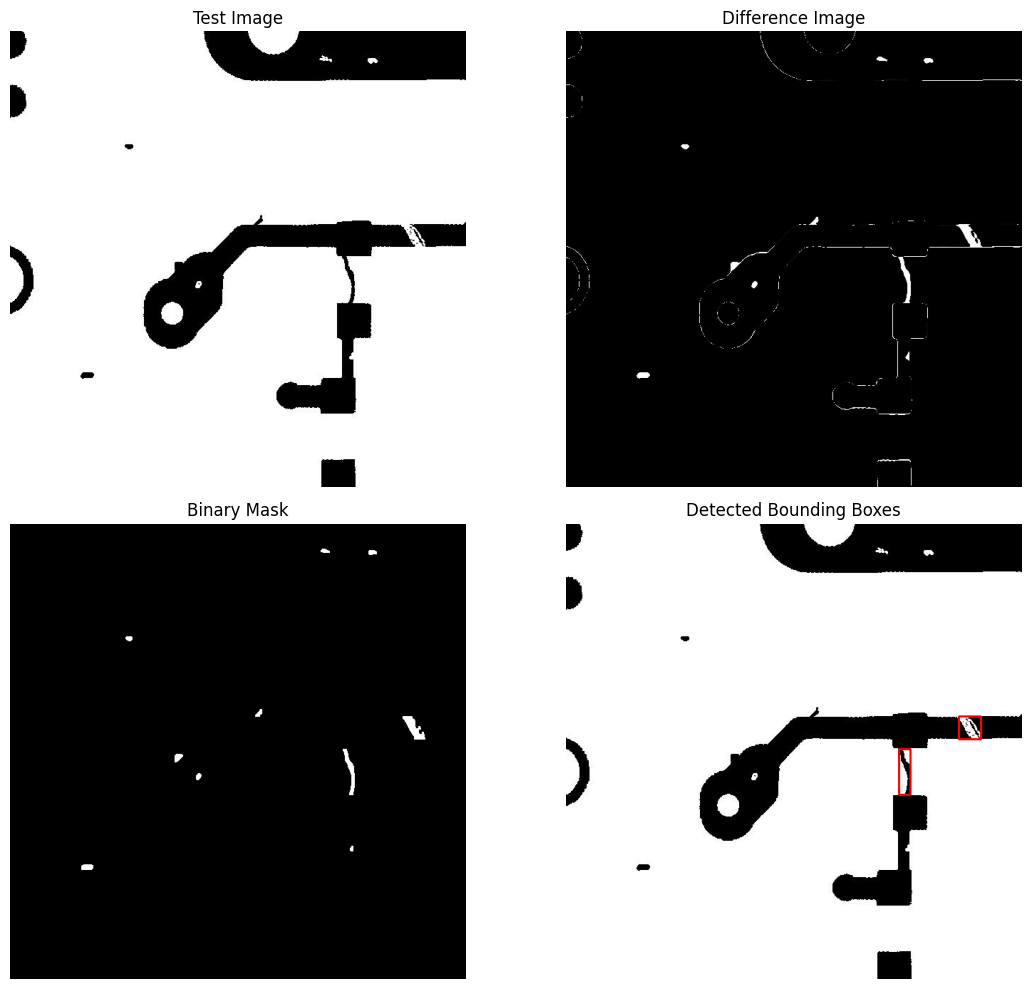

In [13]:
# Draw detected boxes on the test image
result = test.copy()

for x1, y1, x2, y2 in boxes:
    cv2.rectangle(
        result,
        (x1, y1),
        (x2 - 1, y2 - 1),
        (0, 0, 255),
        2
    )

# Display the pipeline stages
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(test, cv2.COLOR_BGR2RGB))
plt.title("Test Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(diff, cmap="gray")
plt.title("Difference Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(mask, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Detected Bounding Boxes")
plt.axis("off")

plt.tight_layout()
plt.show()

#### 4.7.5 Final Configuration Verification

Runs the final configuration (no blur, fixed threshold 50, no morphology, minimum area 200, no padding) on the same image.

In [19]:
# Test the configuration
final_diff, final_mask, final_boxes = run_pipeline(
    test,
    temp,
    blur="none",
    method="fixed",
    thresh=50,
    morph=False,
    min_area=200,
    pad=0
)

print("Number of boxes:", len(final_boxes))
print("Detected boxes:", final_boxes)

Number of boxes: 2
Detected boxes: [(458, 313, 507, 382), (508, 271, 640, 304)]


## 5. Evaluation

The evaluator compares the predicted boxes with the DeepPCB ground truth. A prediction matches a ground-truth box when their IoU is greater than 0.33, and each box can be matched only once. It counts TP, FP and FN, then calculates Precision, Recall and F1-score. Localization recall is also reported separately for Open and Short defects.

The first cell saves the code as `evaluate.py`. The second cell runs its built-in example, which uses made-up boxes and is not a DeepPCB result.

In [ ]:
%%writefile evaluate.py
# -*- coding: utf-8 -*-
"""Untitled0.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1ovqTM3TyEtenVhM_V_CmpnJrfkrZNBvu
"""

# ARTI 403 — Group 2
#  Evaluation Metrics for PCB Defect Detection
# My contribution:
# I evaluate the bounding boxes produced by the PCB defect detector.
# I compare them with the DeepPCB ground-truth boxes using IoU and
# calculate TP, FP, FN, precision, recall, and F1.
# I also report localization recall separately for Open and Short defects.

IOU_THRESHOLD = 0.33


def iou(box_a, box_b):
    """Calculate the intersection over union of two bounding boxes."""
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    width = max(0, min(ax2, bx2) - max(ax1, bx1))
    height = max(0, min(ay2, by2) - max(ay1, by1))
    intersection = width * height

    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def count_matches(pred, gt):
    """Count correct detections, false detections, and missed defects."""
    # DeepPCB class IDs: 1 = Open, 2 = Short.
    labels = {"1": "Open", "open": "Open", "2": "Short", "short": "Short"}

    targets = []
    for x1, y1, x2, y2, defect_type in gt:
        defect = labels.get(str(defect_type).strip().lower())
        if defect is not None:
            targets.append(((x1, y1, x2, y2), defect))

    # Collect valid matches and check the highest IoU first.
    candidates = []
    for pred_index, pred_box in enumerate(pred):
        for gt_index, (gt_box, _) in enumerate(targets):
            overlap = iou(pred_box, gt_box)
            if overlap > IOU_THRESHOLD:
                candidates.append((-overlap, pred_index, gt_index))

    counts = {
        "Open": {"TP": 0, "FP": None, "FN": 0},
        "Short": {"TP": 0, "FP": None, "FN": 0},
    }
    matched_pred = set()
    matched_gt = set()

    for _, pred_index, gt_index in sorted(candidates):
        # Each predicted box and each true box can be used only once.
        if pred_index not in matched_pred and gt_index not in matched_gt:
            matched_pred.add(pred_index)
            matched_gt.add(gt_index)
            defect = targets[gt_index][1]
            counts[defect]["TP"] += 1

    for gt_index, (_, defect) in enumerate(targets):
        if gt_index not in matched_gt:
            counts[defect]["FN"] += 1

    counts["Combined"] = {
        "TP": len(matched_gt),
        "FP": len(pred) - len(matched_pred),
        "FN": len(targets) - len(matched_gt),
    }
    return counts


def calculate_metrics(counts):
    """Calculate precision, recall, and F1 from the detection counts."""
    tp, fp, fn = counts["TP"], counts["FP"], counts["FN"]
    recall = tp / (tp + fn) if tp + fn else 0.0

    # The detector does not predict class labels, so class-specific
    # false positives, precision, and F1 are not applicable.
    if fp is None:
        precision = None
        f1 = None
    else:
        precision = tp / (tp + fp) if tp + fp else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall
            else 0.0
        )

    return {**counts, "P": precision, "R": recall, "F1": f1}


def evaluate(pred, gt):
    """Return the combined metrics for a single image."""
    return calculate_metrics(count_matches(pred, gt)["Combined"])


def evaluate_dataset(samples):
    """Sum counts across all images before calculating the metrics."""
    totals = count_matches([], [])

    for pred, gt in samples:
        image_counts = count_matches(pred, gt)
        for group, counts in image_counts.items():
            for metric, value in counts.items():
                if value is not None:
                    totals[group][metric] += value

    return {
        group: calculate_metrics(counts)
        for group, counts in totals.items()
    }


# EXAMPLE: Made-up boxes to demonstrate how the evaluator works.
# These numbers are not the final DeepPCB test results.
if __name__ == "__main__":
    # Predictions: (x1, y1, x2, y2)
    pred = [
        (0, 0, 10, 10),    # Correct match with an Open defect
        (0, 0, 9, 10),     # Duplicate prediction
        (20, 0, 30, 10),   # Correct match with a Short defect
    ]

    # Ground truth: (x1, y1, x2, y2, defect_type)
    gt = [
        (0, 0, 10, 10, 1),   # Open
        (20, 0, 30, 10, 2),  # Short
        (40, 0, 50, 10, 1),  # Open defect missed by the detector
    ]

    results = evaluate_dataset([(pred, gt)])

    print("Example results (synthetic data):")
    for group, metrics in results.items():
        display_metrics = {
            key: "N/A" if value is None else round(value, 4)
            for key, value in metrics.items()
        }
        print(group, display_metrics)

In [ ]:
%run evaluate.py

Example results (synthetic data):
Open {'TP': 1, 'FP': 'N/A', 'FN': 1, 'P': 'N/A', 'R': 0.5, 'F1': 'N/A'}
Short {'TP': 1, 'FP': 'N/A', 'FN': 0, 'P': 'N/A', 'R': 1.0, 'F1': 'N/A'}
Combined {'TP': 2, 'FP': 1, 'FN': 1, 'P': 0.6667, 'R': 0.6667, 'F1': 0.6667}


## 6. Experiments and Results

This part runs the experiments on the development split (1,000 image pairs) and the final run on the test split (500 image pairs). Every experiment is saved to a CSV file.

The experiments code loads the dataset from `DeepPCB-master.zip` and the modules from `preprocess (1).py` and `evaluate (1).py`. The first cell below prepares these names from the files saved in the earlier sections.

In [ ]:
import os
import shutil

# the experiments code uses these file names
shutil.copy("preprocess.py", "preprocess (1).py")
shutil.copy("evaluate.py", "evaluate (1).py")

# DeepPCB-master.zip is built from the dataset downloaded in section 1
if not os.path.exists("DeepPCB-master.zip"):
    shutil.copytree("DeepPCB", "DeepPCB-master", ignore=shutil.ignore_patterns(".git"), dirs_exist_ok=True)
    shutil.make_archive("DeepPCB-master", "zip", root_dir=".", base_dir="DeepPCB-master")

### 6.1 Dataset setup

Extracts the dataset zip, checks that the files exist, and loads one test image.

In [1]:

from pathlib import Path
import zipfile

zip_path = Path("DeepPCB-master.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(".")

print("DeepPCB extracted successfully!")



DeepPCB extracted successfully!


In [2]:

from pathlib import Path

image = Path("DeepPCB-master/PCBData/group00041/00041/00041000_test.jpg")

print("Image found:", image.exists())



Image found: True


In [3]:

from pathlib import Path

dataset = Path("DeepPCB-master/PCBData")

print("Dataset found:", dataset.exists())

images = list(dataset.rglob("*_test.jpg"))
print("Number of test images:", len(images))

if images:
    print("Example image:", images[0])



Dataset found: True
Number of test images: 1500
Example image: DeepPCB-master\PCBData\group92000\92000\92000000_test.jpg


Image loaded: True
Image shape: (640, 640)


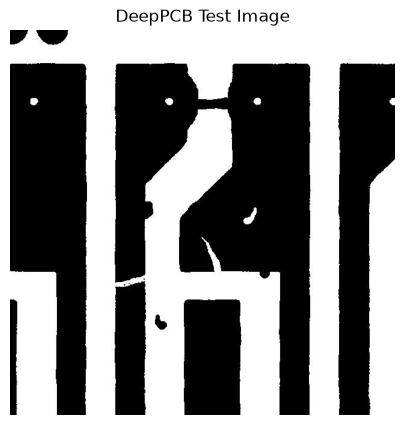

In [4]:

import cv2
import matplotlib.pyplot as plt

image_path = str(images[0])

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

print("Image loaded:", image is not None)

if image is not None:
    print("Image shape:", image.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap="gray")
    plt.title("DeepPCB Test Image")
    plt.axis("off")
    plt.show()



### 6.2 Loading the modules

Prints the saved module files (`detection.py`, `evaluate (1).py`, and `preprocess (1).py`) to check that they are the expected versions.

In [5]:

from pathlib import Path

code = Path("detection.py").read_text(encoding="utf-8-sig")

print(code[:12000])


import cv2

def find_boxes(binary, min_area=100, pad=0):
    # Find contours in the binary image
    contours, _ = cv2.findContours(
        binary.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []
    height, width = binary.shape[:2]

    for contour in contours:
        # Ignore small regions
        area = cv2.contourArea(contour)

        if area >= min_area:
            # Get bounding box coordinates
            x, y, w, h = cv2.boundingRect(contour)

            # Add padding without exceeding image boundaries
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(width, x + w + pad)
            y2 = min(height, y + h + pad)

            boxes.append((x1, y1, x2, y2))

    return boxes



In [6]:

from pathlib import Path

code = Path("evaluate (1).py").read_text(
    encoding="utf-8-sig"
)

print(code[:20000])


# -*- coding: utf-8 -*-
"""Untitled0.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1ovqTM3TyEtenVhM_V_CmpnJrfkrZNBvu
"""

# ARTI 403 — Group 2
#  Evaluation Metrics for PCB Defect Detection
# My contribution:
# I evaluate the bounding boxes produced by the PCB defect detector.
# I compare them with the DeepPCB ground-truth boxes using IoU and
# calculate TP, FP, FN, precision, recall, and F1.
# I also report localization recall separately for Open and Short defects.

IOU_THRESHOLD = 0.33


def iou(box_a, box_b):
    """Calculate the intersection over union of two bounding boxes."""
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    width = max(0, min(ax2, bx2) - max(ax1, bx1))
    height = max(0, min(ay2, by2) - max(ay1, by1))
    intersection = width * height

    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - intersection

    return intersectio

In [7]:

from pathlib import Path

code = Path("preprocess (1).py").read_text(
    encoding="utf-8-sig"
)

print(code[:20000])


"""
Role 2 - Preprocessing & Subtraction
ARTI 403 - Group 2 - Automated PCB Defect Detection

Interface (agreed between roles):
    difference(test, temp, blur, k) -> diff image

    test  : defective image (BGR or grayscale, numpy array)
    temp  : defect-free template image (same size as test)
    blur  : "none" | "gaussian" | "median"
    k     : filter size (odd number, e.g. 3, 5, 7). Ignored when blur="none".

Returns a single-channel uint8 image where bright pixels show
where the test image differs from the template (possible defects).
"""

import cv2

# Settings that Role 6 can change in experiments
BLUR_OPTIONS = ("none", "gaussian", "median")
DEFAULT_BLUR = "gaussian"
DEFAULT_K = 5


def to_gray(img):
    """Convert to grayscale if the image has 3 channels."""
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img


def denoise(gray, blur=DEFAULT_BLUR, k=DEFAULT_K):
    """Apply the chosen noise-removal filter to a grayscale image."""
    bl

### 6.3 Test on one image

Runs the baseline (no blur, fixed threshold 50, no minimum area) on one image, then compares its boxes with the ground truth file of that image.

Test image found: True
Template found: True
Number of predicted boxes: 432


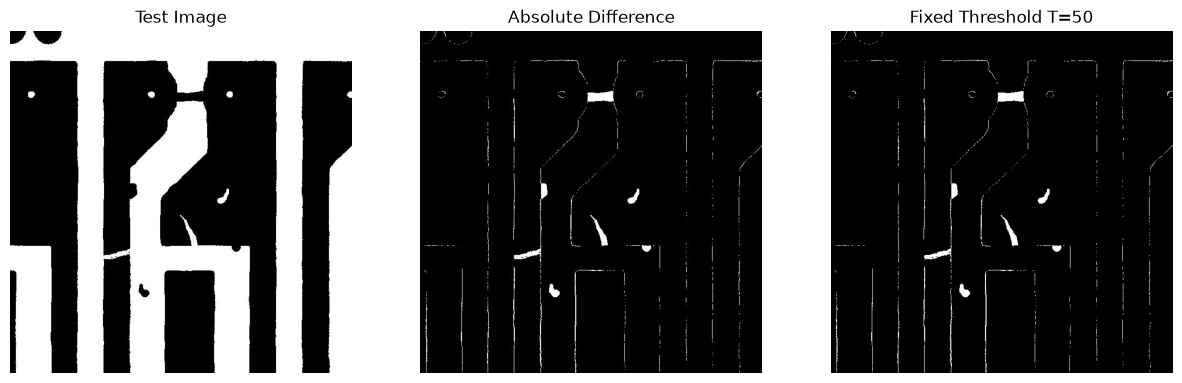

In [8]:

import cv2
import runpy
import matplotlib.pyplot as plt
from pathlib import Path

# Load your teammates' functions
preprocess = runpy.run_path("preprocess (1).py")
detector = runpy.run_path("detection.py")

difference = preprocess["difference"]
find_boxes = detector["find_boxes"]

# Select one PCB image pair
test_path = images[0]
temp_path = Path(
    str(test_path).replace("_test.jpg", "_temp.jpg")
)

test_img = cv2.imread(str(test_path))
temp_img = cv2.imread(str(temp_path))

print("Test image found:", test_img is not None)
print("Template found:", temp_img is not None)

if test_img is None or temp_img is None:
    raise FileNotFoundError("A PCB image pair is missing.")

# Baseline: no filtering
diff = difference(
    test_img,
    temp_img,
    blur="none",
    k=5
)

# Fixed threshold T = 50
_, binary = cv2.threshold(
    diff, 50, 255, cv2.THRESH_BINARY
)

# Detect bounding boxes
boxes = find_boxes(
    binary,
    min_area=0,
    pad=0
)

print("Number of predicted boxes:", len(boxes))

# Display the processing results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(test_img, cmap=None)
axes[0].set_title("Test Image")

axes[1].imshow(diff, cmap="gray")
axes[1].set_title("Absolute Difference")

axes[2].imshow(binary, cmap="gray")
axes[2].set_title("Fixed Threshold T=50")

for ax in axes:
    ax.axis("off")

plt.show()


In [9]:

from pathlib import Path

# Show the selected test image
print("Test image:", test_path)

# Find its corresponding annotation file
image_id = test_path.stem.replace("_test", "")

annotation_files = list(
    Path("DeepPCB-master").rglob(image_id + ".txt")
)

print("Matching annotation files:", len(annotation_files))

for file in annotation_files:
    print("Annotation:", file)
    print("Contents:")
    print(file.read_text(encoding="utf-8"))


Test image: DeepPCB-master\PCBData\group92000\92000\92000000_test.jpg
Matching annotation files: 1
Annotation: DeepPCB-master\PCBData\group92000\92000_not\92000000.txt
Contents:
162 397 243 436 1
296 102 377 141 2
308 334 360 415 3
207 275 247 323 4
405 386 441 422 4
378 285 419 332 6
231 463 270 507 5



In [10]:

import runpy

# Load your teammate's evaluation functions
evaluation = runpy.run_path("evaluate (1).py")
evaluate = evaluation["evaluate"]
count_matches = evaluation["count_matches"]

# Read the annotation file found earlier
annotation_path = annotation_files[0]

gt = []

with open(annotation_path, "r") as file:
    for line in file:
        values = list(map(int, line.strip().split()))

        if len(values) == 5:
            gt.append(tuple(values))

# Evaluate the baseline predictions
results = evaluate(boxes, gt)

print("Ground-truth boxes:", len(gt))
print("Predicted boxes:", len(boxes))

print("True Positives:", results["TP"])
print("False Positives:", results["FP"])
print("False Negatives:", results["FN"])

print(f"Precision: {results['P'] * 100:.2f}%")
print(f"Recall: {results['R'] * 100:.2f}%")
print(f"F1-score: {results['F1'] * 100:.2f}%")


Ground-truth boxes: 7
Predicted boxes: 432
True Positives: 1
False Positives: 431
False Negatives: 1
Precision: 0.23%
Recall: 50.00%
F1-score: 0.46%


### 6.4 Development and test splits

Finds the split files and reads the 1,000 development images (`trainval.txt`) and the 500 test images (`test.txt`).

In [11]:

from pathlib import Path

root = Path("DeepPCB-master")

# Find text files that may define dataset splits
split_files = [
    p for p in root.rglob("*.txt")
    if "train" in p.name.lower()
    or "test" in p.name.lower()
    or "val" in p.name.lower()
]

print("Possible split files:")

for p in split_files[:30]:
    print(p)

print("Total possible split files:", len(split_files))


Possible split files:
DeepPCB-master\PCBData\test.txt
DeepPCB-master\PCBData\trainval.txt
DeepPCB-master\tools\examples\test.txt
Total possible split files: 3


In [13]:
from pathlib import Path

root = Path("DeepPCB-master/PCBData")

train_file = root / "trainval.txt"
test_file = root / "test.txt"

train_lines = [
    line.strip()
    for line in train_file.read_text().splitlines()
    if line.strip()
]

test_lines = [
    line.strip()
    for line in test_file.read_text().splitlines()
    if line.strip()
]

print("Development images:", len(train_lines))
print("Test images:", len(test_lines))

print("First 3 Development entries:")
for line in train_lines[:3]:
    print(line)

print("First 3 Test entries:")
for line in test_lines[:3]:
    print(line)


Development images: 1000
Test images: 500
First 3 Development entries:
group20085/20085/20085000.jpg group20085/20085_not/20085000.txt
group20085/20085/20085001.jpg group20085/20085_not/20085001.txt
group20085/20085/20085002.jpg group20085/20085_not/20085002.txt
First 3 Test entries:
group20085/20085/20085291.jpg group20085/20085_not/20085291.txt
group20085/20085/20085292.jpg group20085/20085_not/20085292.txt
group20085/20085/20085293.jpg group20085/20085_not/20085293.txt


### 6.5 Baseline

Baseline on the development split: grayscale difference, fixed threshold 50, and contours with no minimum area. The other experiments are compared with this one.

In [15]:

import cv2
import runpy
import pandas as pd
from pathlib import Path

# Load teammates' functions
preprocess = runpy.run_path("preprocess (1).py")
detector = runpy.run_path("detection.py")
evaluation = runpy.run_path("evaluate (1).py")

difference = preprocess["difference"]
find_boxes = detector["find_boxes"]
evaluate_dataset = evaluation["evaluate_dataset"]

root = Path("DeepPCB-master/PCBData")

def run_baseline(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        # Build correct DeepPCB image paths
        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        # Read image pair
        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError(
                f"Missing image: {test_path} or {temp_path}"
            )

        if not annotation_path.exists():
            raise FileNotFoundError(
                f"Missing annotation: {annotation_path}"
            )

        # Baseline: no filtering
        diff = difference(
            test_img,
            temp_img,
            blur="none",
            k=5
        )

        # Fixed threshold
        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        # Bounding boxes
        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        # Read ground truth
        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 100 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


# Run on Development only
baseline_results = run_baseline(train_lines)

combined = baseline_results["Combined"]

print("\nBASELINE DEVELOPMENT RESULTS")
print("TP:", combined["TP"])
print("FP:", combined["FP"])
print("FN:", combined["FN"])

print(f"Precision: {combined['P'] * 100:.2f}%")
print(f"Recall: {combined['R'] * 100:.2f}%")
print(f"F1-score: {combined['F1'] * 100:.2f}%")

# Save results
baseline_row = pd.DataFrame([{
    "Configuration": "Baseline",
    "Precision": combined["P"],
    "Recall": combined["R"],
    "F1": combined["F1"],
    "TP": combined["TP"],
    "FP": combined["FP"],
    "FN": combined["FN"]
}])

baseline_row.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nSaved: baseline_development.csv")



Processed 100 images
Processed 200 images
Processed 300 images
Processed 400 images
Processed 500 images
Processed 600 images
Processed 700 images
Processed 800 images
Processed 900 images
Processed 1000 images

BASELINE DEVELOPMENT RESULTS
TP: 488
FP: 473021
FN: 1823
Precision: 0.10%
Recall: 21.12%
F1-score: 0.21%

Saved: baseline_development.csv


### 6.6 Gaussian blur

Same as the baseline, with a Gaussian blur (k = 5) before the difference.

In [16]:

import pandas as pd

def run_gaussian(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="gaussian",
            k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []
        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()
                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


gaussian_results = run_gaussian(train_lines)
g = gaussian_results["Combined"]

print("\nGAUSSIAN DEVELOPMENT RESULTS")
print("TP:", g["TP"])
print("FP:", g["FP"])
print("FN:", g["FN"])

print(f"Precision: {g['P']*100:.2f}%")
print(f"Recall: {g['R']*100:.2f}%")
print(f"F1-score: {g['F1']*100:.2f}%")

# Add the new experiment to your CSV file
previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Gaussian blur k=5",
    "Precision": g["P"],
    "Recall": g["R"],
    "F1": g["F1"],
    "TP": g["TP"],
    "FP": g["FP"],
    "FN": g["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nGaussian experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

GAUSSIAN DEVELOPMENT RESULTS
TP: 522
FP: 244258
FN: 1789
Precision: 0.21%
Recall: 22.59%
F1-score: 0.42%

Gaussian experiment saved!


### 6.7 Median blur

Same as the baseline, with a median blur (k = 5) before the difference.

In [17]:

def run_median(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="median",
            k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


median_results = run_median(train_lines)
m = median_results["Combined"]

print("\nMEDIAN DEVELOPMENT RESULTS")
print("TP:", m["TP"])
print("FP:", m["FP"])
print("FN:", m["FN"])

print(f"Precision: {m['P']*100:.2f}%")
print(f"Recall: {m['R']*100:.2f}%")
print(f"F1-score: {m['F1']*100:.2f}%")

# Add Median results to existing CSV
previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Median blur k=5",
    "Precision": m["P"],
    "Recall": m["R"],
    "F1": m["F1"],
    "TP": m["TP"],
    "FP": m["FP"],
    "FN": m["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nMedian experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

MEDIAN DEVELOPMENT RESULTS
TP: 560
FP: 293800
FN: 1751
Precision: 0.19%
Recall: 24.23%
F1-score: 0.38%

Median experiment saved!


### 6.8 Otsu thresholding

Replaces the fixed threshold with Otsu thresholding (no blur).

In [18]:

def run_otsu(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="none",
            k=5
        )

        # Otsu thresholding
        _, binary = cv2.threshold(
            diff,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


otsu_results = run_otsu(train_lines)
o = otsu_results["Combined"]

print("\nOTSU DEVELOPMENT RESULTS")
print("TP:", o["TP"])
print("FP:", o["FP"])
print("FN:", o["FN"])

print(f"Precision: {o['P']*100:.2f}%")
print(f"Recall: {o['R']*100:.2f}%")
print(f"F1-score: {o['F1']*100:.2f}%")

previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Otsu thresholding",
    "Precision": o["P"],
    "Recall": o["R"],
    "F1": o["F1"],
    "TP": o["TP"],
    "FP": o["FP"],
    "FN": o["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nOtsu experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

OTSU DEVELOPMENT RESULTS
TP: 488
FP: 472480
FN: 1823
Precision: 0.10%
Recall: 21.12%
F1-score: 0.21%

Otsu experiment saved!


### 6.9 Adaptive thresholding

Replaces the fixed threshold with adaptive thresholding (no blur).

In [19]:

def run_adaptive(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="none",
            k=5
        )

        # Adaptive Gaussian Thresholding
        binary = cv2.adaptiveThreshold(
            diff,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            31,
            -25
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


adaptive_results = run_adaptive(train_lines)
a = adaptive_results["Combined"]

print("\nADAPTIVE DEVELOPMENT RESULTS")
print("TP:", a["TP"])
print("FP:", a["FP"])
print("FN:", a["FN"])

print(f"Precision: {a['P']*100:.2f}%")
print(f"Recall: {a['R']*100:.2f}%")
print(f"F1-score: {a['F1']*100:.2f}%")

previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Adaptive thresholding",
    "Precision": a["P"],
    "Recall": a["R"],
    "F1": a["F1"],
    "TP": a["TP"],
    "FP": a["FP"],
    "FN": a["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nAdaptive experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

ADAPTIVE DEVELOPMENT RESULTS
TP: 488
FP: 492590
FN: 1823
Precision: 0.10%
Recall: 21.12%
F1-score: 0.20%

Adaptive experiment saved!


### 6.10 Opening and closing

Tests opening, closing, and opening then closing with kernel sizes 3, 5, and 7 after the fixed threshold.

In [20]:

import cv2
import pandas as pd
import numpy as np

def run_morphology(split_lines, operation, kernel_size):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        # Same baseline preprocessing
        diff = difference(
            test_img, temp_img,
            blur="none", k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        kernel = np.ones(
            (kernel_size, kernel_size), np.uint8
        )

        if operation == "opening":
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_OPEN, kernel
            )

        elif operation == "closing":
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_CLOSE, kernel
            )

        elif operation == "opening_closing":
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_OPEN, kernel
            )
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_CLOSE, kernel
            )

        else:
            raise ValueError("Invalid operation")

        boxes = find_boxes(
            binary, min_area=0, pad=0
        )

        gt = []
        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()
                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

    return evaluate_dataset(samples)["Combined"]


experiments = []

for operation in ["opening", "closing", "opening_closing"]:
    for k in [3, 5, 7]:

        print(f"Running {operation}, kernel={k}...")

        result = run_morphology(
            train_lines, operation, k
        )

        experiments.append({
            "Configuration": f"{operation} {k}x{k}",
            "Precision": result["P"],
            "Recall": result["R"],
            "F1": result["F1"],
            "TP": result["TP"],
            "FP": result["FP"],
            "FN": result["FN"]
        })

        print(
            f"F1: {result['F1']*100:.2f}% | "
            f"Precision: {result['P']*100:.2f}% | "
            f"Recall: {result['R']*100:.2f}%"
        )

# Save morphology results separately
morphology_df = pd.DataFrame(experiments)

morphology_df.to_csv(
    "morphology_development.csv",
    index=False
)

# Merge with previous experiments
previous = pd.read_csv("baseline_development.csv")

updated = pd.concat(
    [previous, morphology_df],
    ignore_index=True
)

updated.to_csv(
    "results_development.csv",
    index=False
)

print("\nAll morphology experiments completed!")
print("Saved: results_development.csv")

display(
    morphology_df[
        ["Configuration", "Precision", "Recall", "F1"]
    ]
)


Running opening, kernel=3...
F1: 1.35% | Precision: 0.75% | Recall: 7.10%
Running opening, kernel=5...
F1: 1.57% | Precision: 1.04% | Recall: 3.20%
Running opening, kernel=7...
F1: 0.97% | Precision: 0.83% | Recall: 1.17%
Running closing, kernel=3...
F1: 0.29% | Precision: 0.15% | Recall: 23.67%
Running closing, kernel=5...
F1: 0.36% | Precision: 0.18% | Recall: 25.62%
Running closing, kernel=7...
F1: 0.44% | Precision: 0.22% | Recall: 25.92%
Running opening_closing, kernel=3...
F1: 1.74% | Precision: 0.99% | Recall: 7.62%
Running opening_closing, kernel=5...
F1: 1.97% | Precision: 1.33% | Recall: 3.81%
Running opening_closing, kernel=7...
F1: 1.23% | Precision: 1.08% | Recall: 1.43%

All morphology experiments completed!
Saved: results_development.csv


,Configuration,Precision,Recall,F1
0,opening 3x3,0.007474,0.070965,0.013523
1,opening 5x5,0.010379,0.032021,0.015676
2,opening 7x7,0.008331,0.011683,0.009726
3,closing 3x3,0.001460,0.236694,0.002903
4,closing 5x5,0.001829,0.256166,0.003633
5,closing 7x7,0.002219,0.259195,0.004401
6,opening_closing 3x3,0.009851,0.076158,0.017445
7,opening_closing 5x5,0.013265,0.038079,0.019676
8,opening_closing 7x7,0.010848,0.014280,0.012330


### 6.11 Minimum contour area

Tests minimum contour areas of 5, 10, 20, 100, 150, 200, and 300 px² with the fixed threshold. The best F1-score on the development split comes from 200 px².

In [21]:

import cv2
import pandas as pd
from pathlib import Path

def run_min_area(split_lines, min_area):
    samples = []

    for line in split_lines:
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img, temp_img,
            blur="none", k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        boxes = find_boxes(
            binary,
            min_area=min_area,
            pad=0
        )

        gt = []
        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()
                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

    return evaluate_dataset(samples)["Combined"]


area_results = []

for area in [5, 10, 20, 100, 150, 200, 300]:
    print(f"Running min_area={area}...")

    result = run_min_area(train_lines, area)

    area_results.append({
        "Configuration": f"Minimum contour area {area} px2",
        "Precision": result["P"],
        "Recall": result["R"],
        "F1": result["F1"],
        "TP": result["TP"],
        "FP": result["FP"],
        "FN": result["FN"]
    })

    print(
        f"Precision: {result['P']*100:.2f}% | "
        f"Recall: {result['R']*100:.2f}% | "
        f"F1: {result['F1']*100:.2f}%"
    )


area_df = pd.DataFrame(area_results)

area_df.to_csv(
    "minimum_area_development.csv",
    index=False
)

# Merge with previous experiments
previous = pd.read_csv("results_development.csv")

updated = pd.concat(
    [previous, area_df],
    ignore_index=True
)

updated.to_csv(
    "results_development.csv",
    index=False
)

print("\nMinimum-area experiments completed!")
print("Saved: results_development.csv")

display(area_df)


Running min_area=5...
Precision: 1.71% | Recall: 21.12% | F1: 3.17%
Running min_area=10...
Precision: 2.06% | Recall: 21.12% | F1: 3.75%
Running min_area=20...
Precision: 2.60% | Recall: 21.07% | F1: 4.63%
Running min_area=100...
Precision: 6.00% | Recall: 17.52% | F1: 8.94%
Running min_area=150...
Precision: 7.61% | Recall: 14.41% | F1: 9.96%
Running min_area=200...
Precision: 9.09% | Recall: 12.55% | F1: 10.54%
Running min_area=300...
Precision: 10.81% | Recall: 8.70% | F1: 9.64%

Minimum-area experiments completed!
Saved: results_development.csv


,Configuration,Precision,Recall,F1,TP,FP,FN
0,Minimum contour area 5 px2,0.017141,0.211164,0.031708,488,27982,1823
1,Minimum contour area 10 px2,0.020566,0.211164,0.037481,488,23241,1823
2,Minimum contour area 20 px2,0.026004,0.210731,0.046295,487,18241,1824
3,Minimum contour area 100 px2,0.059991,0.175249,0.089384,405,6346,1906
4,Minimum contour area 150 px2,0.076080,0.144093,0.099581,333,4044,1978
5,Minimum contour area 200 px2,0.090909,0.125487,0.105435,290,2900,2021
6,Minimum contour area 300 px2,0.108123,0.086975,0.096403,201,1658,2110


### 6.12 Final test results

Runs the selected configuration (minimum area 200 px²) once on the 500 test images and saves the result.

In [22]:

import pandas as pd

# Final configuration selected using Development
final_area = 200

# Evaluate on the held-out Test split
final_results = run_min_area(test_lines, final_area)

print("\nFINAL TEST RESULTS")
print("Configuration: Minimum contour area = 200 px2")
print("TP:", final_results["TP"])
print("FP:", final_results["FP"])
print("FN:", final_results["FN"])

print(f"Precision: {final_results['P'] * 100:.2f}%")
print(f"Recall: {final_results['R'] * 100:.2f}%")
print(f"F1-score: {final_results['F1'] * 100:.2f}%")

# Save final test results
final_df = pd.DataFrame([{
    "Configuration": "Minimum contour area 200 px2",
    "Split": "Test",
    "Precision": final_results["P"],
    "Recall": final_results["R"],
    "F1": final_results["F1"],
    "TP": final_results["TP"],
    "FP": final_results["FP"],
    "FN": final_results["FN"]
}])

final_df.to_csv("final_test_results.csv", index=False)

print("\nSaved: final_test_results.csv")



FINAL TEST RESULTS
Configuration: Minimum contour area = 200 px2
TP: 115
FP: 1797
FN: 1022
Precision: 6.01%
Recall: 10.11%
F1-score: 7.54%

Saved: final_test_results.csv


### 6.13 Combined configuration

Tests one combined configuration: Gaussian blur (k = 5), fixed threshold 50, opening then closing (3 × 3), and minimum area 200 px².

In [23]:

import cv2
import numpy as np
import pandas as pd

def run_combined(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError(
                f"Missing image pair: {test_path}"
            )

        # Step 1: Gaussian filtering and subtraction
        diff = difference(
            test_img,
            temp_img,
            blur="gaussian",
            k=5
        )

        # Step 2: Fixed threshold
        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        # Step 3: Opening and Closing
        kernel = np.ones((3, 3), np.uint8)

        binary = cv2.morphologyEx(
            binary, cv2.MORPH_OPEN, kernel
        )

        binary = cv2.morphologyEx(
            binary, cv2.MORPH_CLOSE, kernel
        )

        # Step 4: Minimum contour area
        boxes = find_boxes(
            binary,
            min_area=200,
            pad=0
        )

        # Step 5: Ground truth
        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


combined_results = run_combined(train_lines)
c = combined_results["Combined"]

print("\nCOMBINED DEVELOPMENT RESULTS")
print("TP:", c["TP"])
print("FP:", c["FP"])
print("FN:", c["FN"])

print(f"Precision: {c['P'] * 100:.2f}%")
print(f"Recall: {c['R'] * 100:.2f}%")
print(f"F1-score: {c['F1'] * 100:.2f}%")

combined_df = pd.DataFrame([{
    "Configuration": "Combined Gaussian5 OpenClose3 Area200",
    "Precision": c["P"],
    "Recall": c["R"],
    "F1": c["F1"],
    "TP": c["TP"],
    "FP": c["FP"],
    "FN": c["FN"]
}])

combined_df.to_csv(
    "combined_development.csv",
    index=False
)

print("\nSaved: combined_development.csv")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

COMBINED DEVELOPMENT RESULTS
TP: 417
FP: 7807
FN: 1894
Precision: 5.07%
Recall: 18.04%
F1-score: 7.92%

Saved: combined_development.csv


### 6.14 Results table

Merges the development results into one table sorted by F1-score and checks the saved CSV files.

In [24]:

import pandas as pd

# Load 21 completed experiments
development = pd.read_csv("results_development.csv")

# Load the additional combined experiment
combined = pd.read_csv("combined_development.csv")

# Add Combined only if it is not already present
development = development[
    ~development["Configuration"].str.startswith(
        "Combined Gaussian5", na=False
    )
]

all_results = pd.concat(
    [development, combined],
    ignore_index=True
)

# Sort configurations by F1-score
all_results = all_results.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

# Save complete experiment table
all_results.to_csv(
    "role6_development_final.csv",
    index=False
)

print("Total experiments:", len(all_results))
print("\nTop 10 configurations:")

display(
    all_results[
        ["Configuration", "Precision", "Recall", "F1"]
    ].head(10).style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

print("\nSaved: role6_development_final.csv")


Total experiments: 22

Top 10 configurations:


,Configuration,Precision,Recall,F1
0,Minimum contour area 200 px2,9.09%,12.55%,10.54%
1,Minimum contour area 150 px2,7.61%,14.41%,9.96%
2,Minimum contour area 300 px2,10.81%,8.70%,9.64%
3,Minimum contour area 100 px2,6.00%,17.52%,8.94%
4,Combined Gaussian5 OpenClose3 Area200,5.07%,18.04%,7.92%
5,Minimum contour area 20 px2,2.60%,21.07%,4.63%
6,Minimum contour area 10 px2,2.06%,21.12%,3.75%
7,Minimum contour area 5 px2,1.71%,21.12%,3.17%
8,opening_closing 5x5,1.33%,3.81%,1.97%
9,opening_closing 3x3,0.99%,7.62%,1.74%



Saved: role6_development_final.csv


In [25]:

from pathlib import Path
import pandas as pd

files = [
    "baseline_development.csv",
    "morphology_development.csv",
    "minimum_area_development.csv",
    "combined_development.csv",
    "role6_development_final.csv",
    "final_test_results.csv"
]

print("ROLE 6 FILE CHECK")
print("-" * 35)

for name in files:
    if Path(name).exists():
        print("OK:", name)
    else:
        print("MISSING:", name)

print("\nDEVELOPMENT SUMMARY")
dev = pd.read_csv("role6_development_final.csv")
print("Total experiments:", len(dev))
print("Best configuration:", dev.iloc[0]["Configuration"])
print(f"Best F1: {dev.iloc[0]['F1'] * 100:.2f}%")

print("\nFINAL TEST SUMMARY")
test = pd.read_csv("final_test_results.csv")
print(test.to_string(index=False))


ROLE 6 FILE CHECK
-----------------------------------
OK: baseline_development.csv
OK: morphology_development.csv
OK: minimum_area_development.csv
OK: combined_development.csv
OK: role6_development_final.csv
OK: final_test_results.csv

DEVELOPMENT SUMMARY
Total experiments: 22
Best configuration: Minimum contour area 200 px2
Best F1: 10.54%

FINAL TEST SUMMARY
               Configuration Split  Precision   Recall       F1  TP   FP   FN
Minimum contour area 200 px2  Test   0.060146 0.101143 0.075435 115 1797 1022


In [26]:

import pandas as pd

dev = pd.read_csv("role6_development_final.csv")
test = pd.read_csv("final_test_results.csv")

print("Development experiments:", len(dev))
print("Unique configurations:", dev["Configuration"].nunique())
print("Missing values:")
print(dev.isnull().sum())

print("\nBest development configuration:")
print(dev.loc[dev["F1"].idxmax()].to_string())

print("\nFinal test configuration:")
print(test.to_string(index=False))


Development experiments: 22
Unique configurations: 22
Missing values:
Configuration    0
Precision        0
Recall           0
F1               0
TP               0
FP               0
FN               0
dtype: int64

Best development configuration:
Configuration    Minimum contour area 200 px2
Precision                            0.090909
Recall                               0.125487
F1                                   0.105435
TP                                        290
FP                                       2900
FN                                       2021

Final test configuration:
               Configuration Split  Precision   Recall       F1  TP   FP   FN
Minimum contour area 200 px2  Test   0.060146 0.101143 0.075435 115 1797 1022


### 6.15 Visualization

Draws one successful and one partially missed localization from the test split, with the ground truth and the predicted boxes, and saves the figure.

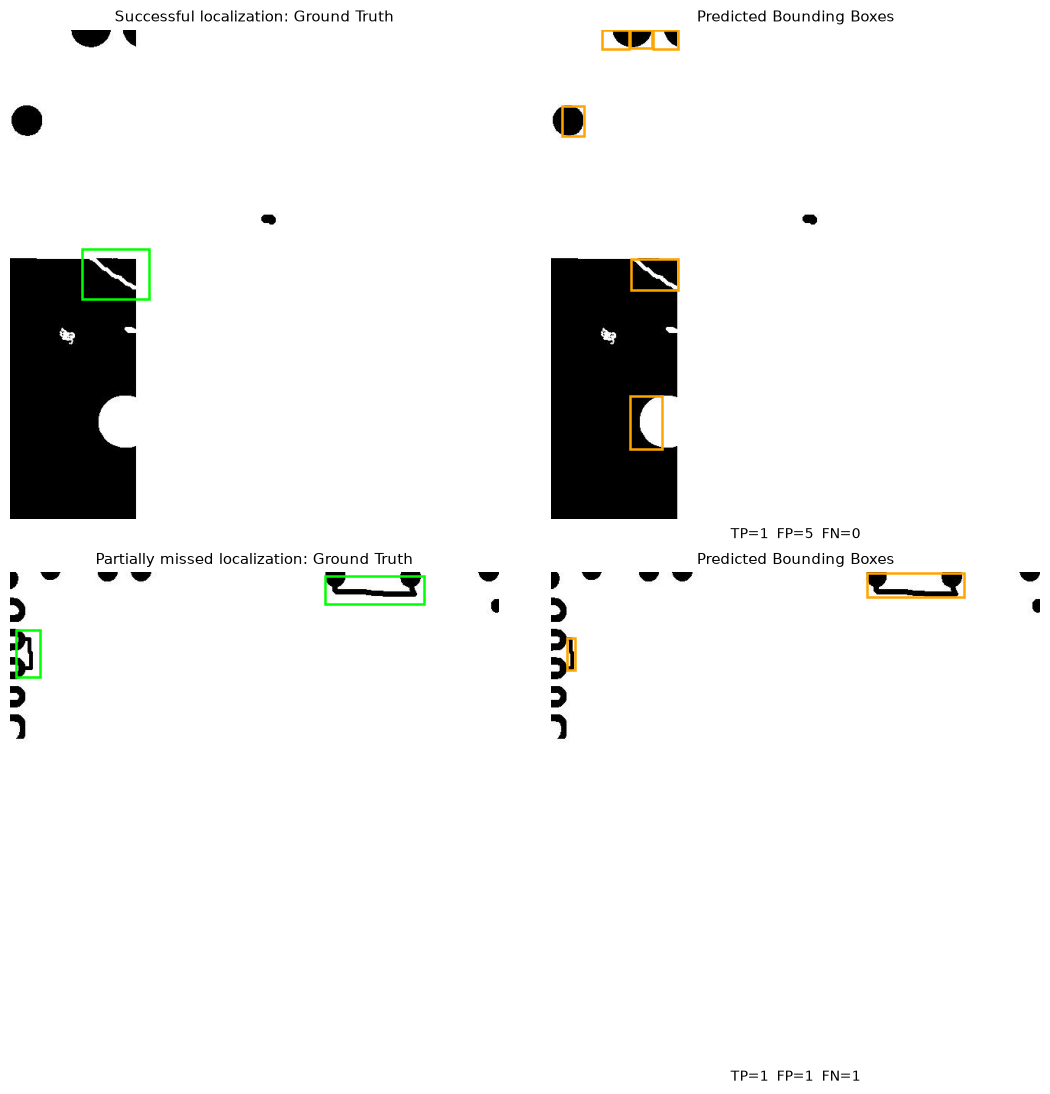

Saved: Role6_Visualization.png
Success image ID: 13000198
Missed image ID: 20085311


In [27]:

import cv2
import runpy
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

# Load the original functions from your teammates
preprocess = runpy.run_path("preprocess (1).py")
detector = runpy.run_path("detection.py")
evaluation = runpy.run_path("evaluate (1).py")

difference = preprocess["difference"]
find_boxes = detector["find_boxes"]
count_matches = evaluation["count_matches"]

root = Path("DeepPCB-master/PCBData")

# Final selected configuration
MIN_AREA = 200
THRESHOLD = 50

def process_sample(line):
    image_rel, annotation_rel = line.split()
    base = root / image_rel

    test_path = base.with_name(base.stem + "_test.jpg")
    temp_path = base.with_name(base.stem + "_temp.jpg")
    annotation_path = root / annotation_rel

    test = cv2.imread(str(test_path), cv2.IMREAD_GRAYSCALE)
    temp = cv2.imread(str(temp_path), cv2.IMREAD_GRAYSCALE)

    if test is None or temp is None:
        raise FileNotFoundError(str(test_path))

    diff = difference(test, temp, blur="none", k=5)

    _, binary = cv2.threshold(
        diff, THRESHOLD, 255, cv2.THRESH_BINARY
    )

    predictions = find_boxes(
        binary, min_area=MIN_AREA, pad=0
    )

    gt = []
    with open(annotation_path, "r") as f:
        for row in f:
            values = row.strip().split()
            if len(values) == 5:
                gt.append(tuple(map(int, values)))

    counts = count_matches(predictions, gt)["Combined"]

    return test, predictions, gt, counts, base.stem


# Find examples from the held-out test split
success = None
missed = None

for line in test_lines:
    sample = process_sample(line)
    counts = sample[3]

    if success is None and counts["TP"] > 0 and counts["FN"] == 0:
        success = sample

    if missed is None and counts["TP"] > 0 and counts["FN"] > 0:
        missed = sample

    if success is not None and missed is not None:
        break

# Fallback if no fully matched example exists
if success is None:
    for line in test_lines:
        sample = process_sample(line)
        if sample[3]["TP"] > 0:
            success = sample
            break

if success is None or missed is None:
    raise ValueError(
        "Suitable examples were not found. "
        "Please inspect the test results."
    )


def draw_boxes(ax, image, boxes, color, title):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    for box in boxes:
        x1, y1, x2, y2 = box[:4]
        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor=color,
            linewidth=1.8
        )
        ax.add_patch(rect)

    ax.set_title(title, fontsize=11)
    ax.axis("off")


fig, axes = plt.subplots(2, 2, figsize=(11, 11))

for row, (sample, label) in enumerate([
    (success, "Successful localization"),
    (missed, "Partially missed localization")
]):
    image, predictions, gt, counts, image_id = sample

    targets = [box for box in gt if box[4] in (1, 2)]

    draw_boxes(
        axes[row, 0], image, targets,
        "lime", f"{label}: Ground Truth"
    )

    draw_boxes(
        axes[row, 1], image, predictions,
        "orange", "Predicted Bounding Boxes"
    )

    axes[row, 1].text(
        0.5, -0.04,
        f"TP={counts['TP']}  FP={counts['FP']}  FN={counts['FN']}",
        transform=axes[row, 1].transAxes,
        ha="center",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    "Role6_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Role6_Visualization.png")
print("Success image ID:", success[4])
print("Missed image ID:", missed[4])


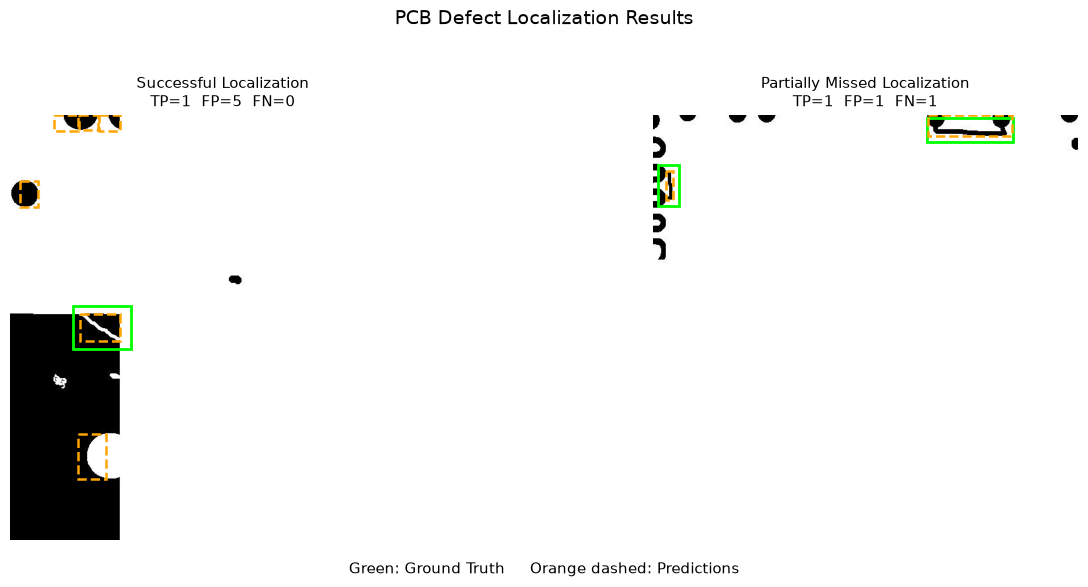

In [28]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, sample, title in zip(
    axes,
    [success, missed],
    ["Successful Localization", "Partially Missed Localization"]
):
    image, predictions, gt, counts, image_id = sample

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    # Ground truth: green
    for box in gt:
        if box[4] in (1, 2):
            x1, y1, x2, y2 = box[:4]
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                fill=False,
                edgecolor="lime",
                linewidth=2
            ))

    # Predictions: orange
    for box in predictions:
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            fill=False,
            edgecolor="orange",
            linewidth=1.8,
            linestyle="--"
        ))

    ax.set_title(
        f"{title}\nTP={counts['TP']}  "
        f"FP={counts['FP']}  FN={counts['FN']}",
        fontsize=11
    )
    ax.axis("off")

fig.suptitle(
    "PCB Defect Localization Results",
    fontsize=14
)

fig.text(
    0.5, 0.04,
    "Green: Ground Truth     Orange dashed: Predictions",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])

plt.savefig(
    "Role6_Final_Figure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
